# Detección de tiña corporis con procesamiento clásico de imágenes
**PSIB 2026 Q2 — Grupo 9 (Del Carril, Escobar, Uthurralt)**

Pregunta: ¿se puede distinguir tiña corporis (TC) de dermatitis de contacto / eczema ("Otras") usando
características de color y textura, sin entrenar un modelo?

Idea central: la TC suele tener un **borde activo** (anillo rojo y descamado) con el **centro más claro**;
las lesiones inflamatorias de "Otras" tienden a ser placas más homogéneas.

## Pipeline
| Etapa | Qué hace | Archivo |
|---|---|---|
| 1 | Enmascarar fondo blanco + RGB → CIELAB | `etapas/e1_mascara_lab.py` |
| 2 | Mejoramiento (suavizado de artefactos JPEG, normalización respecto de la piel sana) | *pendiente* |
| 3 | Segmentación de la lesión | *pendiente* |
| 4 | Separación borde / centro de la lesión (morfología) | *pendiente* |
| 5 | Características: color (a*) y textura (GLCM) en borde vs. centro | *pendiente* |
| 6 | Decisión estadística: comparación entre clases y elección del umbral | *pendiente* |
| 7 | Evaluación en testeo | *pendiente* |

Las funciones de cada etapa están en `etapas/`; este notebook solo las llama y muestra resultados.

**Regla de trabajo:** las etapas 1–6 se desarrollan y ajustan **solo con Entrenamiento** (`CONJUNTO = "Entrenamiento"`). Testeo no se mira ni se usa para elegir nada; se carga una única vez en la sección 7, con todos los parámetros y umbrales ya fijados.

In [ ]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from etapas.datos import listar_dataset, verificar_separacion, cargar_rgb
from etapas import e1_mascara_lab as e1

RUTA_DATASET = Path("Dataset_reducido")
CONJUNTO = "Entrenamiento"   # Testeo se usa solo en la sección 7
RUTA_RESULTADOS = Path("resultados")   # se crea sola; cada etapa guarda en resultados/etapaN/

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 0. Dataset

In [ ]:
verificar_separacion(RUTA_DATASET)   # ninguna imagen en ambos conjuntos

df = listar_dataset(RUTA_DATASET, CONJUNTO)
print(f"Conjunto: {CONJUNTO} — {len(df)} imágenes")
df.groupby(["clase", "subtipo"]).size().rename("n").to_frame()

Conjunto: Entrenamiento — 37 imágenes


n
clase subtipo    
Otras CD       14
      EC       10
TC    TC       13

## 1. Enmascarado del fondo y conversión a Lab

**Por qué se enmascara:** varias imágenes tienen el fondo recortado en blanco. Si se dejan esos píxeles, puede afectar mucho a las mediciones que comparan los tonos de los píxeles.
Ej. Otsu termina separando fondo vs. resto y la GLCM mide pares blanco-blanco y el salto piel/fondo en vez de la textura de la piel.

**Máscara:** píxeles claros y sin color (HSV: V ≥ 235, S ≤ 25) que forman una región **conectada al borde** de la imagen.
Ese último criterio es importante porque la TC tiene una descamación blanquecina adentro de la lesión que también es clara y poco saturada,
pero como queda rodeada de piel y no se borra. Después se dilata el fondo unos píxeles para descartar la franja de transición.

**Lab:** separa la luminosidad (L*) del color. El eritema se mide en **a*** (eje verde–rojo) sin que influya
si la foto está más clara u oscura.

In [ ]:
resultados = {id_: e1.procesar_etapa1(cargar_rgb(r)) for id_, r in df["ruta"].items()}
df["frac_fondo"] = pd.Series({k: v["frac_fondo"] for k, v in resultados.items()})

print(f"Imágenes con fondo descartado: {(df['frac_fondo'] > 0).sum()} de {len(df)}")
(df.groupby("clase")["frac_fondo"]
   .agg(con_fondo=lambda s: (s > 0).sum(), n="size", fondo_medio="mean")
   .style.format({"fondo_medio": "{:.1%}"}))

Imágenes con fondo descartado: 15 de 37


,con_fondo,n,fondo_medio
clase,,,
Otras,12,24,11.3%
TC,3,13,2.4%


### Guardado
Se guarda en `resultados/etapa1/<conjunto>/`, por imagen:
- `<id>_mascara.png`: máscara de piel (blanco = piel).
- `<id>_enmascarada.png`: imagen con el fondo en negro, para mirar.
- `<id>_lab.npz`: L*, a*, b* en float y la máscara. **Es lo que lee la etapa 2** (un PNG perdería los decimales y los valores negativos de a*/b*).

In [ ]:
carpeta_e1 = RUTA_RESULTADOS / "etapa1"
for id_, res in resultados.items():
    rutas = e1.guardar_etapa1(res, id_, carpeta_e1 / CONJUNTO)
    df.loc[id_, "ruta_lab"] = rutas["lab"]

print(f"Guardadas {len(resultados)} imágenes en {carpeta_e1.resolve()}")

Guardadas 37 imágenes en C:\Users\ronal\Documents\Q2 2026\PSIB\TP Imagenes\PSIB2026Q2-TPI-Grupo9-DelCarril-Ecobar-Uthurralt\resultados\etapa1


### Ejemplos
- **CD (120)**: mucho fondo blanco recortado.
- **EC (86)**: tiene escamas blancas dentro de la lesión → no deben marcarse como fondo.
- **TC (156)**: anillo típico; en a* el borde debería verse más rojo que el centro.
- **TC (8)**: lesión clara con poco fondo en una esquina.

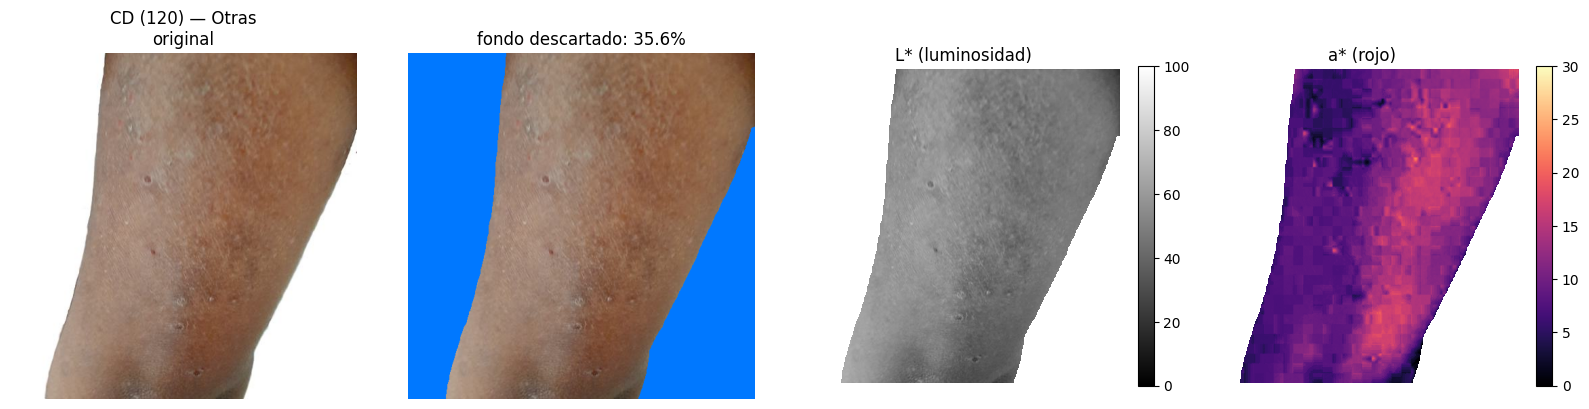

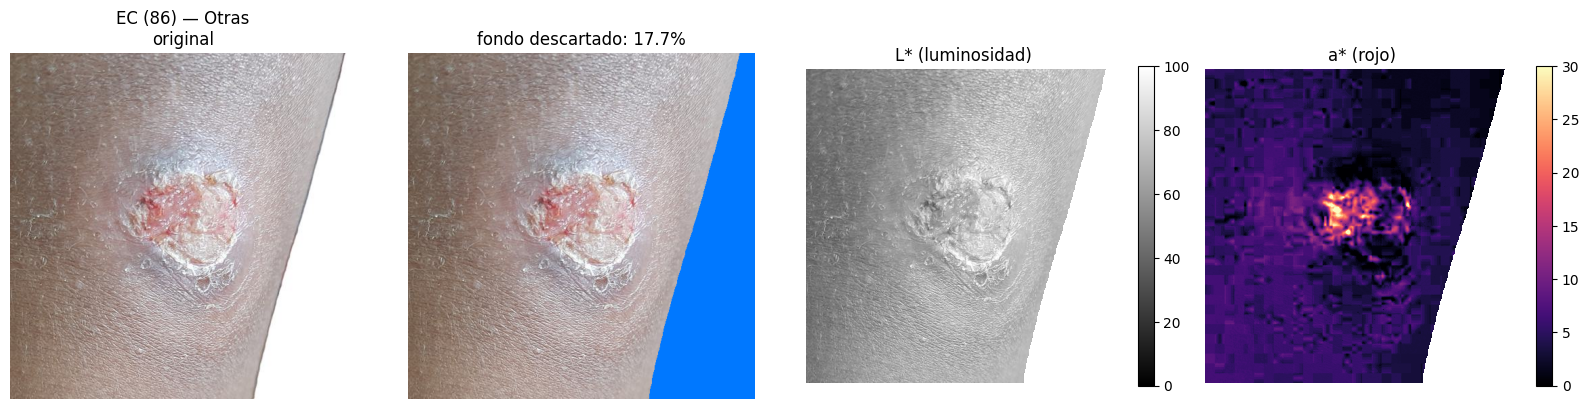

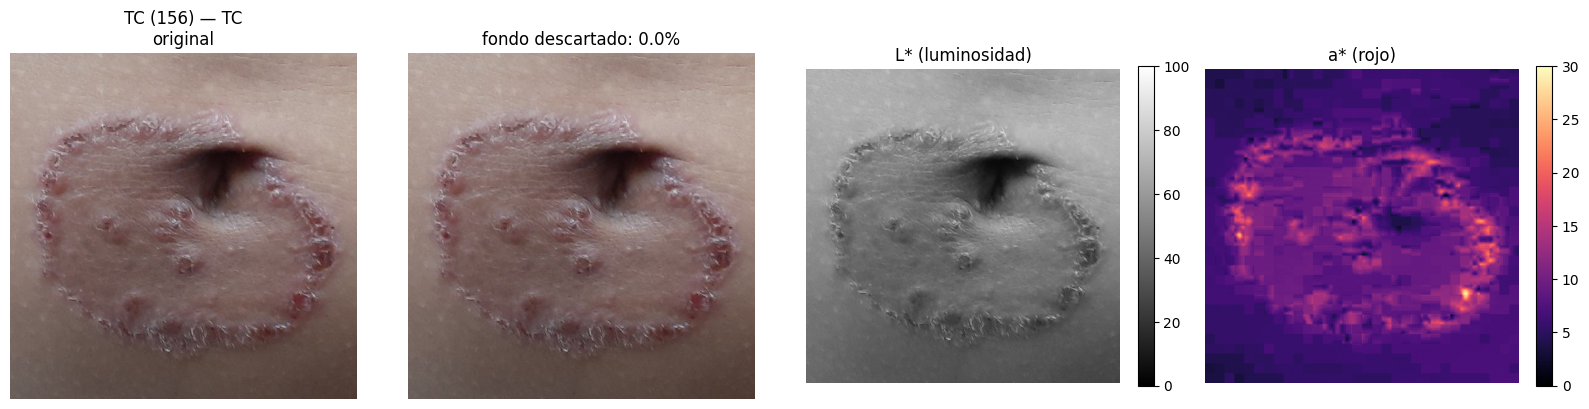

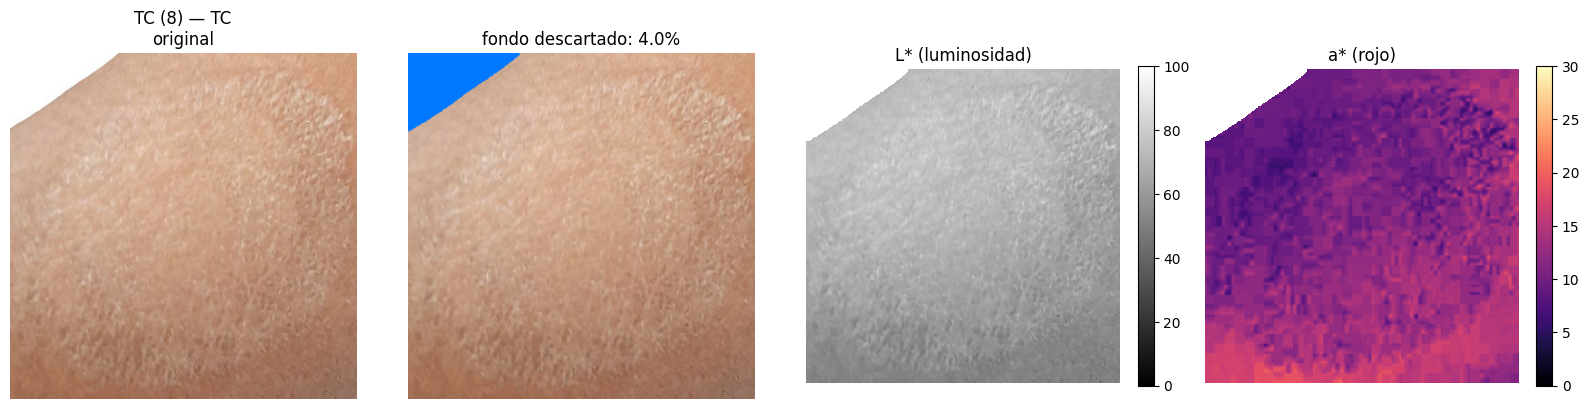

In [ ]:
for id_ in ["CD (120)", "EC (86)", "TC (156)", "TC (8)"]:
    e1.mostrar_etapa1(resultados[id_], titulo=f"{id_} — {df.loc[id_, 'clase']}")
    plt.show()

### Control de todas las máscaras
Fondo descartado en azul --> Para revisar que no se esté comiendo piel ni escamas.

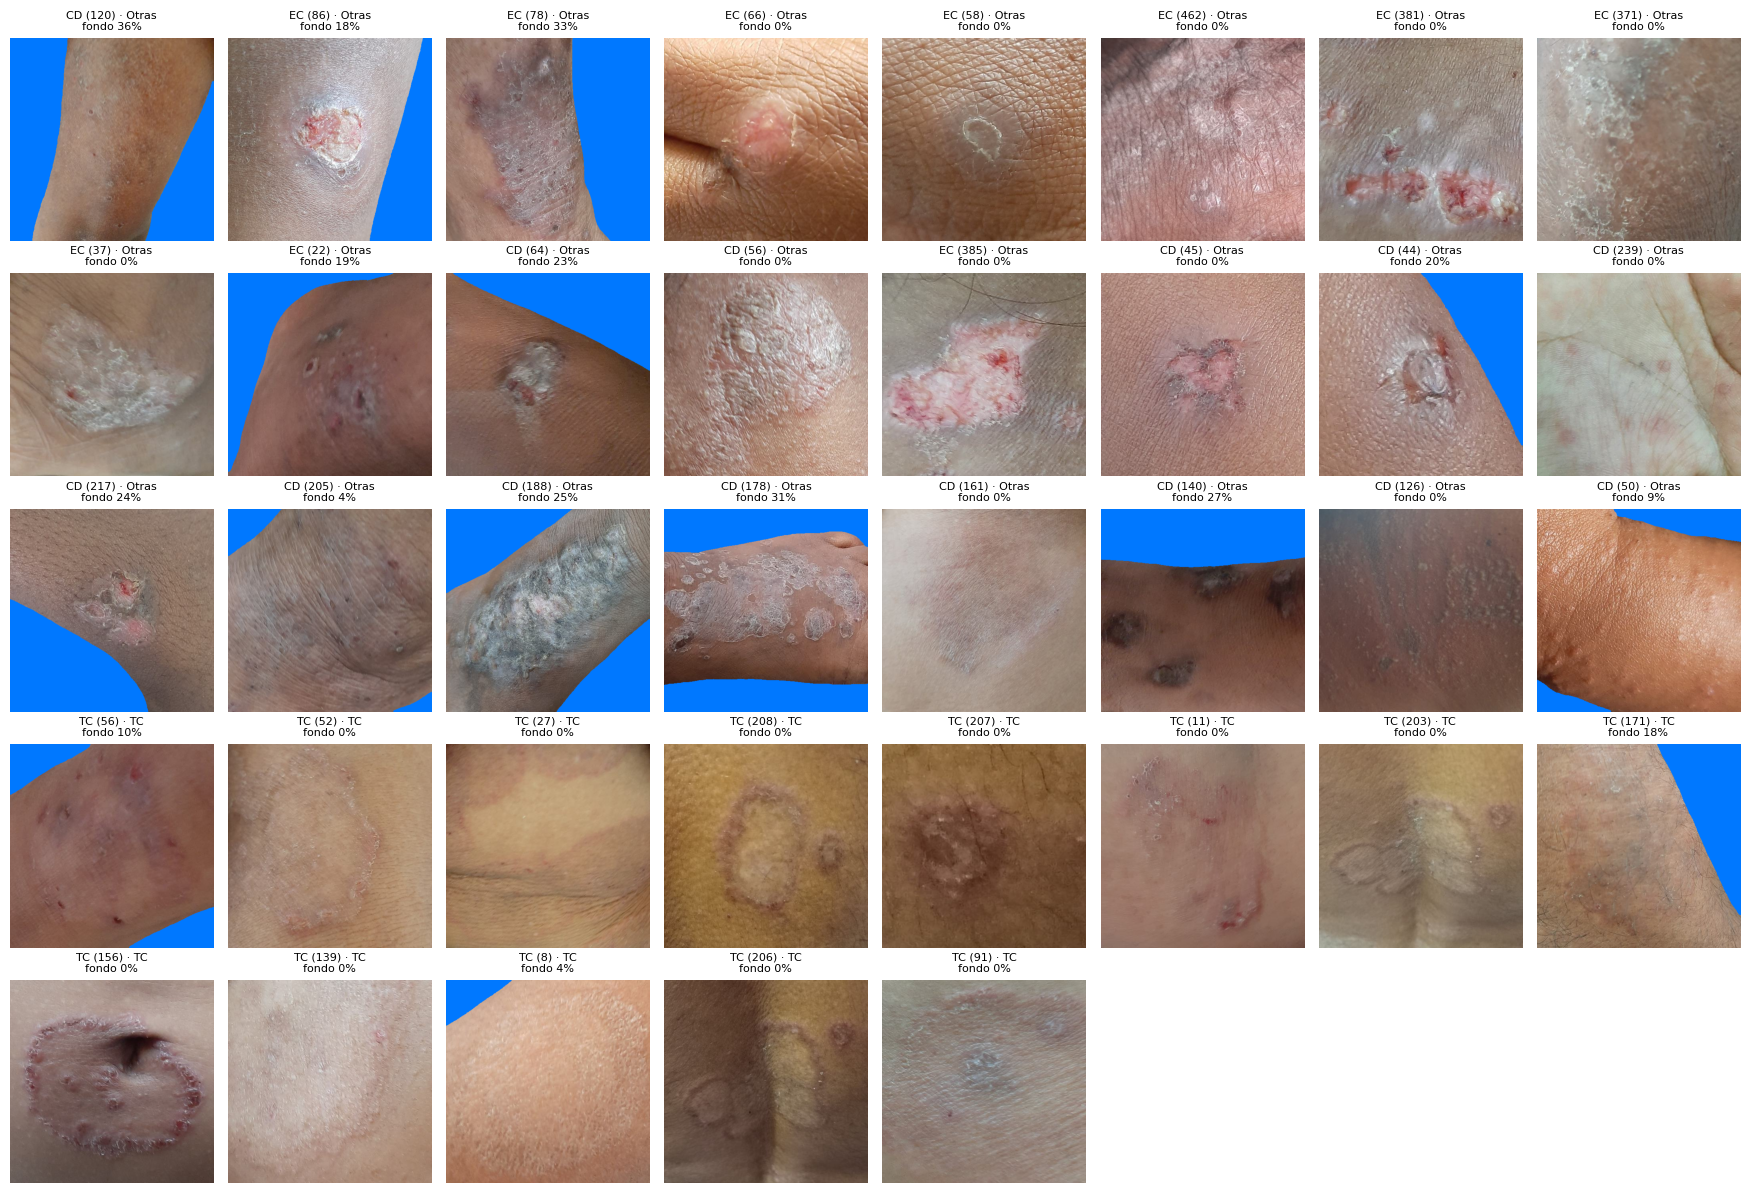

In [ ]:
ids = df.sort_values("clase").index
cols = 8
filas = int(np.ceil(len(ids) / cols))
fig, axs = plt.subplots(filas, cols, figsize=(2.2 * cols, 2.4 * filas))
for ax, id_ in zip(axs.flat, ids):
    r = resultados[id_]
    img = r["rgb"].copy()
    img[~r["mascara"]] = (0, 120, 255)
    ax.imshow(img)
    ax.set_title(f"{id_} · {df.loc[id_, 'clase']}\nfondo {100 * r['frac_fondo']:.0f}%", fontsize=8)
for ax in axs.flat:
    ax.axis("off")
fig.tight_layout()
plt.show()

## 2. Mejoramiento
*Pendiente.*

## 3. Segmentación de la lesión
*Pendiente.*

## 4. Borde vs. centro
*Pendiente.*

## 5. Características
*Pendiente.*

## 6. Decisión estadística
*Pendiente.*

## 7. Evaluación en testeo
*Pendiente.* Se corre una sola vez al final: `listar_dataset(RUTA_DATASET, "Testeo")`, mismas funciones y mismos parámetros/umbrales fijados en las etapas 1–6, sin volver a ajustarlos según el resultado.